In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C4"
DTYPE="HSV"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C4_10,25,"[DATA/TRAINING/C4/C4_10/IMG_6597.HEIC, DATA/TR..."
1,C4_11,27,"[DATA/TRAINING/C4/C4_11/IMG_6727.HEIC, DATA/TR..."
2,C4_12,27,"[DATA/TRAINING/C4/C4_12/IMG_6857.HEIC, DATA/TR..."
3,C4_13,30,"[DATA/TRAINING/C4/C4_13/IMG_6998.HEIC, DATA/TR..."
4,C4_14,27,"[DATA/TRAINING/C4/C4_14/IMG_7250.HEIC, DATA/TR..."
5,C4_15,25,"[DATA/TRAINING/C4/C4_15/IMG_7388.HEIC, DATA/TR..."
6,C4_16,28,"[DATA/TRAINING/C4/C4_16/IMG_7517.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

In [7]:
def hsv_histogram(image, bins):
    #print(mask)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    #The 3D color histogram is extracted from the mask area of the image using the bin number of each channel provided
    hist = cv2.calcHist([image], [0, 1, 2], None, [bins, bins, bins], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    #Return histogram
    return hist

Text(0.5, 1.0, '16% IMG_7561.HEIC')

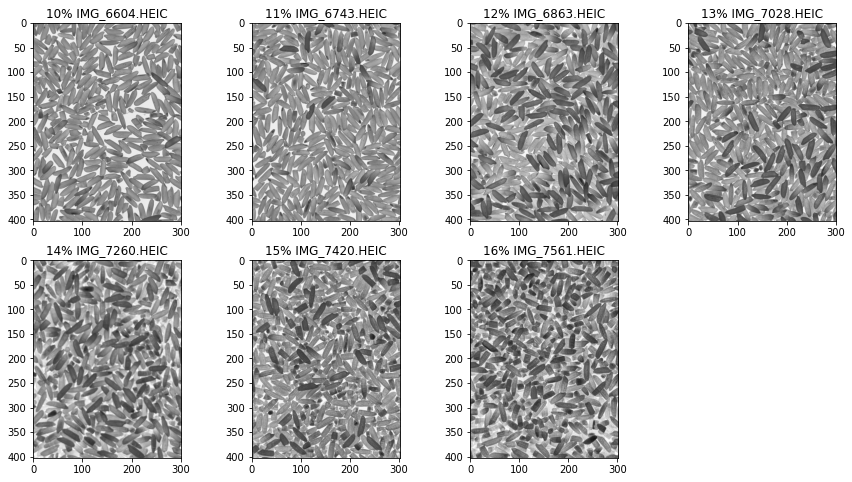

In [8]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [160]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
scale=25
bins=16
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [161]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.000000,0.000003,0.000090,0.004650,0.060769,0.187942,0.134128,0.288254,0.580453,0.631668,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6597.HEIC,10
1,0.000000,0.000017,0.000121,0.005659,0.065091,0.236020,0.150901,0.261794,0.544146,0.627843,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6598.HEIC,10
2,0.000000,0.000121,0.000918,0.005765,0.051377,0.203677,0.201609,0.326880,0.543452,0.570299,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6599.HEIC,10
3,0.000014,0.000014,0.000388,0.006965,0.046118,0.159694,0.157803,0.336890,0.611713,0.572072,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6600.HEIC,10
4,0.000000,0.000020,0.000493,0.008629,0.059735,0.153188,0.156044,0.372901,0.695772,0.493947,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6601.HEIC,10
5,0.000023,0.000010,0.000157,0.002557,0.035512,0.151291,0.142185,0.303809,0.594685,0.610493,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6602.HEIC,10
6,0.000000,0.000017,0.000142,0.003431,0.042159,0.147641,0.159981,0.345405,0.618917,0.567133,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6603.HEIC,10
7,0.000013,0.000009,0.000218,0.001446,0.016740,0.081407,0.153221,0.378085,0.691853,0.492006,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6604.HEIC,10
8,0.000003,0.000013,0.000023,0.000799,0.011233,0.064188,0.141961,0.347878,0.622651,0.588458,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6605.HEIC,10
9,0.000000,0.000000,0.000075,0.000840,0.010108,0.067075,0.156789,0.389990,0.623955,0.536283,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6606.HEIC,10


# Classification

In [162]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [163]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [164]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [165]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [166]:
TYPE="CV"

In [167]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.578947,0.630952,0.571429,0.599717,HSV,C4,RF_C,25,16,1008,756,3
1,2,0.684211,0.788095,0.690476,0.736063,HSV,C4,RF_C,25,16,1008,756,3
2,3,0.578947,0.778912,0.571429,0.659230,HSV,C4,RF_C,25,16,1008,756,3
3,4,0.736842,0.773810,0.738095,0.755531,HSV,C4,RF_C,25,16,1008,756,3
4,5,0.684211,0.761905,0.666667,0.711111,HSV,C4,RF_C,25,16,1008,756,3
5,6,0.526316,0.595238,0.523810,0.557244,HSV,C4,RF_C,25,16,1008,756,3
6,7,0.789474,0.833333,0.809524,0.821256,HSV,C4,RF_C,25,16,1008,756,3
7,8,0.736842,0.797619,0.714286,0.753656,HSV,C4,RF_C,25,16,1008,756,3
8,9,0.368421,0.333333,0.357143,0.344828,HSV,C4,RF_C,25,16,1008,756,3
9,10,0.555556,0.619048,0.547619,0.581147,HSV,C4,RF_C,25,16,1008,756,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C4,RF_C,0.623977,0.619048,0.651978,0.691224


### MLP Classifier

In [170]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [171]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [172]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.473684,0.557143,0.500000,0.527027,HSV,C4,MLP_C,25,16,1008,756,3
1,2,0.684211,0.714286,0.666667,0.689655,HSV,C4,MLP_C,25,16,1008,756,3
2,3,0.368421,0.528571,0.380952,0.442782,HSV,C4,MLP_C,25,16,1008,756,3
3,4,0.631579,0.676190,0.642857,0.659103,HSV,C4,MLP_C,25,16,1008,756,3
4,5,0.421053,0.540476,0.428571,0.478062,HSV,C4,MLP_C,25,16,1008,756,3
5,6,0.736842,0.761905,0.738095,0.749811,HSV,C4,MLP_C,25,16,1008,756,3
6,7,0.578947,0.607143,0.619048,0.613037,HSV,C4,MLP_C,25,16,1008,756,3
7,8,0.578947,0.654762,0.595238,0.623583,HSV,C4,MLP_C,25,16,1008,756,3
8,9,0.736842,0.773810,0.738095,0.755531,HSV,C4,MLP_C,25,16,1008,756,3
9,10,0.500000,0.635714,0.500000,0.559748,HSV,C4,MLP_C,25,16,1008,756,3


In [173]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C4,MLP_C,0.571053,0.580952,0.609834,0.645


### XGBoost Classifier

In [174]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [175]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.631579,0.666667,0.666667,0.666667,HSV,C4,XGB_C,25,16,1008,756,3
1,2,0.526316,0.557143,0.523810,0.539962,HSV,C4,XGB_C,25,16,1008,756,3
2,3,0.684211,0.735714,0.666667,0.699491,HSV,C4,XGB_C,25,16,1008,756,3
3,4,0.526316,0.642857,0.547619,0.591429,HSV,C4,XGB_C,25,16,1008,756,3
4,5,0.526316,0.523810,0.547619,0.535450,HSV,C4,XGB_C,25,16,1008,756,3
5,6,0.526316,0.671429,0.523810,0.588503,HSV,C4,XGB_C,25,16,1008,756,3
6,7,0.684211,0.773810,0.666667,0.716253,HSV,C4,XGB_C,25,16,1008,756,3
7,8,0.684211,0.761905,0.714286,0.737327,HSV,C4,XGB_C,25,16,1008,756,3
8,9,0.473684,0.547619,0.452381,0.495465,HSV,C4,XGB_C,25,16,1008,756,3
9,10,0.722222,0.750000,0.714286,0.731707,HSV,C4,XGB_C,25,16,1008,756,3


In [176]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C4,XGB_C,0.598538,0.602381,0.630225,0.663095


# External validation

In [177]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C4_10,5,"[DATA/TEST/C4/C4_10/IMG_6593.HEIC, DATA/TEST/C..."
1,C4_11,5,"[DATA/TEST/C4/C4_11/IMG_6718.HEIC, DATA/TEST/C..."
2,C4_12,5,"[DATA/TEST/C4/C4_12/IMG_6846.HEIC, DATA/TEST/C..."
3,C4_13,5,"[DATA/TEST/C4/C4_13/IMG_6983.HEIC, DATA/TEST/C..."
4,C4_14,5,"[DATA/TEST/C4/C4_14/IMG_7240.HEIC, DATA/TEST/C..."
5,C4_15,5,"[DATA/TEST/C4/C4_15/IMG_7378.HEIC, DATA/TEST/C..."
6,C4_16,5,"[DATA/TEST/C4/C4_16/IMG_7507.HEIC, DATA/TEST/C..."


In [178]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [179]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [180]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.000000,0.000000,0.000548,0.007365,0.085802,0.375679,0.253176,0.262078,0.407847,0.561431,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6593.HEIC,10
1,0.000000,0.000051,0.000953,0.007098,0.088776,0.329416,0.193590,0.249935,0.443521,0.567799,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6594.HEIC,10
2,0.000000,0.000036,0.000164,0.004803,0.065482,0.243971,0.175927,0.270803,0.527430,0.579676,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6595.HEIC,10
3,0.000004,0.000025,0.000367,0.003865,0.053223,0.196035,0.176919,0.328785,0.579495,0.570921,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6596.HEIC,10
4,0.000000,0.000000,0.000075,0.000840,0.010108,0.067075,0.156789,0.389990,0.623955,0.536283,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_660.HEIC,10
0,0.000004,0.000509,0.003559,0.009713,0.102169,0.399262,0.297289,0.225511,0.375953,0.455214,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6718.HEIC,11
1,0.000000,0.000427,0.002789,0.014105,0.129715,0.363902,0.287712,0.230205,0.379034,0.484506,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6720.HEIC,11
2,0.000000,0.000000,0.000163,0.002320,0.039088,0.171327,0.164327,0.332902,0.587303,0.603317,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6723.HEIC,11
3,0.000000,0.000014,0.001325,0.005374,0.059065,0.190344,0.162356,0.247706,0.533642,0.598223,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6725.HEIC,11
4,0.000000,0.000014,0.001249,0.005444,0.062731,0.200806,0.167956,0.274966,0.594503,0.573316,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6726.HEIC,11


In [181]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [182]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [183]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [184]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [185]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       0.38      0.60      0.46         5
     Class 2       0.50      0.60      0.55         5
     Class 3       0.33      0.20      0.25         5
     Class 4       0.40      0.40      0.40         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.60      0.60      0.60         5

    accuracy                           0.51        35
   macro avg       0.54      0.51      0.52        35
weighted avg       0.54      0.51      0.52        35



## MLP

In [186]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [187]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       0.43      0.60      0.50         5
     Class 2       0.57      0.80      0.67         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.40      0.40      0.40         5
     Class 5       0.75      0.60      0.67         5
     Class 6       0.60      0.60      0.60         5

    accuracy                           0.57        35
   macro avg       0.61      0.57      0.58        35
weighted avg       0.61      0.57      0.58        35



## XGBC

In [188]:
y_pred = modelXGBC.predict(X_test_scale) 

In [189]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.56      1.00      0.71         5
     Class 2       0.50      0.40      0.44         5
     Class 3       0.33      0.40      0.36         5
     Class 4       0.50      0.60      0.55         5
     Class 5       0.25      0.20      0.22         5
     Class 6       0.75      0.60      0.67         5

    accuracy                           0.51        35
   macro avg       0.56      0.51      0.50        35
weighted avg       0.56      0.51      0.50        35

